# 03 · Signatures — Dong 2020 Neuroblastoma

Render the three embryonic-module signatures on the manifold (raw `score_genes` values, as the
reference shows) and make the **Gate 2** call: is a Gast/pSom hub diverging into two arms, or the
non-branching case (Gast/pSom overlap, Crest an inverse/terminal gradient)? Gate 3 is
branching-only.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb   = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name)

dataset: Dong2020_Neuroendocrine


### Load manifold; gene recovery
Scores were computed with the union control pool in step 01. Report the per-module gene recovery
on the shared panel.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.shape[0], '| raw module means:',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 52/81 genes present
pSom: 62/98 genes present
Crest: 80/104 genes present
cells: 47384 | raw module means: {'Gast': 0.1005, 'pSom': 0.2322, 'Crest': -0.0001}


### Gate 2 — module geography (biology, not geometry)
Read the module relationships off the smoothed scores and pseudotime: (i) spatial correlations,
(ii) gradients along pseudotime, (iii) whether Crest is a terminal/inverse readout, and (iv) an
**inverse-gradient vs co-expression-hub** test — the enrichment of jointly pSom&Crest-high cells
relative to independence (<1 = mutually exclusive inverse gradient, not a co-expression hub).

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a],adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
for m,l in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{l}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint = ((pz>0.5)&(cz>0.5)).mean(); exp = (pz>0.5).mean()*(cz>0.5).mean()
print(f'joint pSom&Crest-high enrichment = {joint/exp:.2f} (<1 = inverse gradient, not a hub)')
print('\nGATE 2 = GO (non-branching): Gast/pSom overlap (co-vary), Crest an inverse gradient vs pSom;')
print('single axis, no Gast/pSom hub-and-spoke divergence. GATE 3 = NA (no bifurcation to test).')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.28
  Crest_sm vs Gast_sm: r = -0.10
  Crest_sm vs pSom_sm: r = -0.65
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.629
  pSom_sm: rho = -0.050
  Crest_sm: rho = -0.033
Neural-crest-high decile mean pseudotime = 0.58
Somitogenesis-high decile mean pseudotime = 0.43
Gastrulation-high decile mean pseudotime = 0.18
joint pSom&Crest-high enrichment = 0.38 (<1 = inverse gradient, not a hub)

GATE 2 = GO (non-branching): Gast/pSom overlap (co-vary), Crest an inverse gradient vs pSom;
single axis, no Gast/pSom hub-and-spoke divergence. GATE 3 = NA (no bifurcation to test).


### Signature figures (deliverables) — raw scores, house layout
One panel per module on the house linear layout, **raw** `score_genes` values (smoothing aids the
analysis but the reference deliverable shows raw), `plasma` colormap, with an external colorbar
each — matching the reference `{Gast,pSom,Crest}_signature.pdf` style.

<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


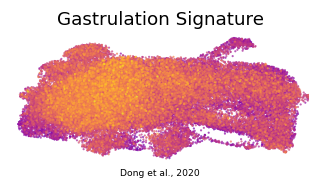

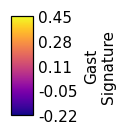

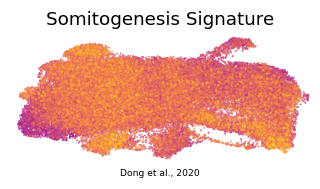

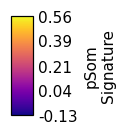

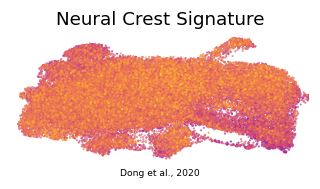

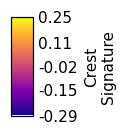

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=8, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (47384, 12113)
